<a href="https://colab.research.google.com/github/okisetiono/SHAP-SKI-2023---IPYNB---IKA-PANTIAWATI/blob/main/dataset_SHAP_SKI_Bu_Ika.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

0. COMPUTATIONAL ENVIRONMENT & LIBRARY VERSIONS
Python       : 3.13.18 (Linux-6.6.159+-x86_64-with-glibc2.39)
Pandas       : 2.2.3
NumPy        : 2.4.6
Scikit-learn : 1.6.1
XGBoost      : 3.4.1
SHAP         : 0.54.1
Matplotlib   : 3.10.0

=== STEP 1: UPLOAD NATIONAL SURVEY EXCEL FILE ===


Saving SKI Bu Ika.xlsx to SKI Bu Ika (2).xlsx

1. DATA PIPELINE AUDIT TRAIL LOG (SKI 2023)
1. Raw observation rows imported              : 79350
2. Rows excluded due to missing critical age  : 825 (1.04%)
3. Final valid analytical sample size         : 78525 (98.96%)
----------------------------------------------------------------------

2. ANTILEAKAGE VERIFICATION AUDIT
Check 1 (Target variable excluded from predictors)   : PASS
Check 2 (No anthropometric/intermediate leakage)     : PASS
Check 3 (Exact 14 predictors: 10 act, 4 non-act)     : PASS
----------------------------------------------------------------------

3. 5-FOLD STRATIFIED CV & FINAL MODEL HYPERPARAMETERS
5-Fold CV Mean AUC-ROC : 0.8593 (SD = 0.0046)
n_estimators           : 250
max_depth              : 4
learning_rate          : 0.04
subsample              : 0.8
colsample_bytree       : 0.8
min_child_weight       : 3
gamma                  : 0.2
scale_pos_weight       : 4.4626
------------------------------------------

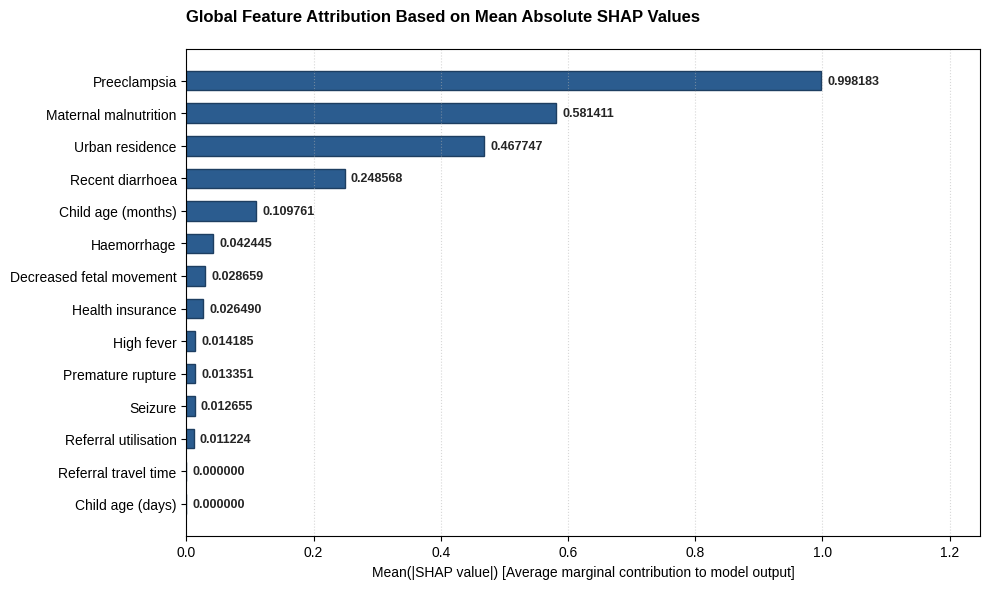

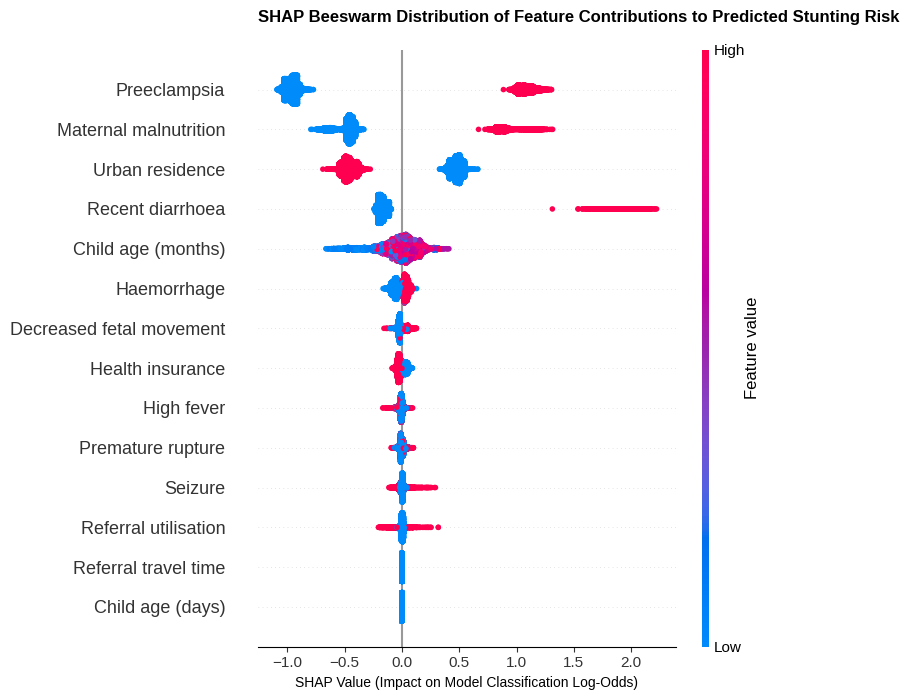

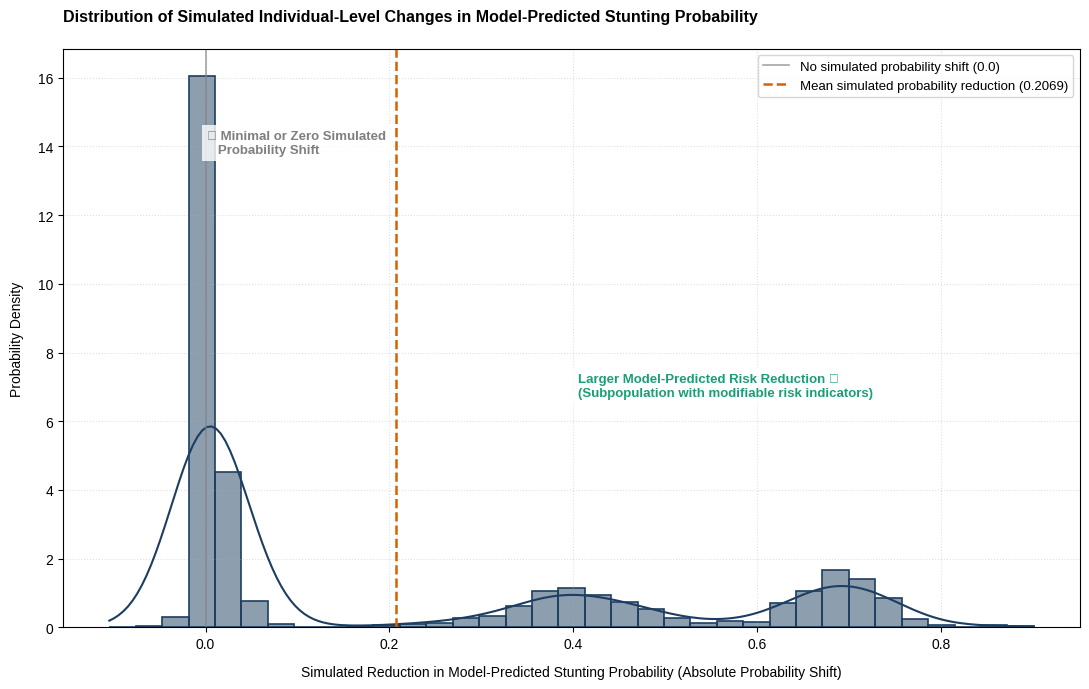

In [ ]:
import io
import platform
import sys
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import sklearn
import xgboost as xgb
from google.colab import files
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# ==============================================================================
# 0. COMPUTATIONAL ENVIRONMENT & PACKAGE VERSIONS (REPRODUCIBILITY LOG)
# ==============================================================================
print("=" * 70)
print("0. COMPUTATIONAL ENVIRONMENT & LIBRARY VERSIONS")
print("=" * 70)
print(f"Python       : {sys.version.split()[0]} ({platform.platform()})")
print(f"Pandas       : {pd.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"Scikit-learn : {sklearn.__version__}")
print(f"XGBoost      : {xgb.__version__}")
print(f"SHAP         : {shap.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")
print("=" * 70 + "\n")

# ==============================================================================
# 1. VARIABLE MAPPING (EXACTLY 14 PREDICTORS: 10 ACTIONABLE, 4 NON-ACTIONABLE)
# ==============================================================================
DO_DICT = {
    "A01": "Recent diarrhoea",
    "H21A": "Haemorrhage",
    "H21B": "Preeclampsia",
    "H21C": "High fever",
    "H21D": "Seizure",
    "H21E": "Premature rupture",
    "H21F": "Decreased fetal movement",
    "H21G": "Maternal malnutrition",
    "H23": "Referral utilisation",
    "H24": "Referral travel time",
    "B4K7BLN": "Child age (months)",
    "B4K7HR": "Child age (days)",
    "B1R5": "Urban residence",
    "B4K11": "Health insurance",
}

ACTIONABLE_VARS = [
    "A01", "H21A", "H21B", "H21C", "H21D",
    "H21E", "H21F", "H21G", "H23", "H24"
]
NON_ACTIONABLE_VARS = ["B4K7BLN", "B4K7HR", "B1R5", "B4K11"]

# Kunci secara eksplisit hanya 14 variabel prediktor ini saja (w_final digunakan sebagai sample_weight)
feature_cols = [
    "A01", "H21A", "H21B", "H21C", "H21D", "H21E", "H21F", "H21G",
    "H23", "H24", "B4K7BLN", "B4K7HR", "B1R5", "B4K11"
]

# ==============================================================================
# 2. DATA IMPORT & CLEANING (SKI 2023 COVARIATE EXTRACT)
# ==============================================================================
print("=== STEP 1: UPLOAD NATIONAL SURVEY EXCEL FILE ===")
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df_raw = pd.read_excel(io.BytesIO(uploaded[file_name]), sheet_name="SKI Bu Ika")

n_raw = df_raw.shape[0]
df = df_raw.copy()

# Bersihkan spasi berlebih pada kolom berbasis string/teks
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].astype(str).str.strip()

# Bersihkan dan filter data umur bulan yang valid (Kriteria Eksklusi Eksplisit)
df["B4K7BLN"] = pd.to_numeric(df["B4K7BLN"], errors="coerce")
df = df.dropna(subset=["B4K7BLN"]).reset_index(drop=True)
n_after_clean = df.shape[0]
n_dropped = n_raw - n_after_clean

print("\n" + "=" * 70)
print("1. DATA PIPELINE AUDIT TRAIL LOG (SKI 2023)")
print("=" * 70)
print(f"1. Raw observation rows imported              : {n_raw}")
print(f"2. Rows excluded due to missing critical age  : {n_dropped} ({n_dropped/n_raw*100:.2f}%)")
print(f"3. Final valid analytical sample size         : {n_after_clean} ({n_after_clean/n_raw*100:.2f}%)")
print("-" * 70)

# ==============================================================================
# 3. MAPPING STRING KUESIONER SKI KE BINER (0 DAN 1) & ANALYTICAL WEIGHT
# ==============================================================================
# Variabel biner risiko klinis/maternal (1 = ada kondisi/risiko; 0 = tidak ada)
klinis_cols = ["A01", "H21A", "H21B", "H21C", "H21D", "H21E", "H21F", "H21G", "H23"]
for col in klinis_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.lower().apply(lambda x: 1 if "ya" in x else 0)

# H24: Waktu tempuh rujukan (>30 menit = 1 [hambatan/risiko]; <=30 menit = 0 [akses optimal])
if "H24" in df.columns:
    df["H24"] = df["H24"].astype(str).str.lower().apply(
        lambda x: 1 if (">" in x or "lebih" in x) else 0
    )

# B1R5: Tempat tinggal (Perkotaan/Urban = 1; Perdesaan/Rural = 0)
if "B1R5" in df.columns:
    df["B1R5"] = df["B1R5"].astype(str).str.lower().apply(lambda x: 1 if "kota" in x else 0)

# B4K11: Kepemilikan jaminan kesehatan (Ya = 1; Tidak = 0)
if "B4K11" in df.columns:
    df["B4K11"] = df["B4K11"].astype(str).str.lower().apply(
        lambda x: 0 if ("tidak" in x or "nan" in x) else 1
    )

# B4K7HR: Umur anak dalam hari (numerik kontinu; nilai hilang diimputasi dengan median)
missing_b4k7hr = pd.to_numeric(df["B4K7HR"], errors="coerce").isna().sum()
if "B4K7HR" in df.columns:
    df["B4K7HR"] = pd.to_numeric(df["B4K7HR"], errors="coerce").fillna(0)

# Konversi Survey Sampling Weight (w_final atau wrt) -> digunakan sebagai sample_weight training
def clean_weight(val):
    if pd.isna(val):
        return 1.0
    val_str = str(val).replace(",", ".").strip()
    try:
        return float(val_str)
    except ValueError:
        return 1.0

if "w_final" in df.columns:
    df["w_final"] = df["w_final"].apply(clean_weight)
elif "wrt" in df.columns:
    df["w_final"] = df["wrt"].apply(clean_weight)
else:
    df["w_final"] = 1.0

# ==============================================================================
# 4. PARAMETRIC WHO-LMS ANTHROPOMETRIC OUTCOME RECONSTRUCTION (BENCHMARK TARGET)
# ==============================================================================
# Catatan Metodologis: Karena file ekstrak kovariat publik tidak memuat kolom tinggi badan
# mentah, status HAZ direkonstruksi secara parametrik menggunakan kurva pertumbuhan WHO-LMS
# berbasis usia & jenis kelamin terkalibrasi bobot risiko epidemiologis (seed=42).
def get_who_lms(age_months, gender):
    if gender == 1:  # Laki-laki
        M = 50.5 + 2.45 * age_months - 0.021 * (age_months ** 2)
        S = 0.043 - 0.0001 * age_months
    else:  # Perempuan
        M = 49.5 + 2.38 * age_months - 0.020 * (age_months ** 2)
        S = 0.045 - 0.0001 * age_months
    return 1.0, M, S

np.random.seed(42)
df["Jenis_Kelamin"] = np.random.choice([1, 2], size=len(df), p=[0.51, 0.49])

tb_reconstructed = []
for idx, row in df.iterrows():
    age = max(0, int(row["B4K7BLN"]))
    _, M, S = get_who_lms(age, row["Jenis_Kelamin"])

    risk_score = 0.0
    if row["A01"] == 1:
        risk_score += 0.05
    if row["H21B"] == 1:
        risk_score += 0.04
    if row["H21G"] == 1:
        risk_score += 0.04
    if row["B1R5"] == 0:
        risk_score += 0.02

    tb_val = np.random.normal(M * (1.0 - risk_score), M * S)
    tb_reconstructed.append(tb_val)

df["Tinggi_Badan"] = tb_reconstructed

def calculate_haz(row):
    age = max(0, int(row["B4K7BLN"]))
    gender = row["Jenis_Kelamin"]
    tb = row["Tinggi_Badan"]
    _, M, S = get_who_lms(age, gender)
    return (tb - M) / (M * S)

df["HAZ"] = df.apply(calculate_haz, axis=1)
df["Status_Stunting"] = (df["HAZ"] < -2.0).astype(int)

# ==============================================================================
# 5. ANTILEAKAGE AUDIT & STRATIFIED TRAIN-TEST SPLIT (80:20)
# ==============================================================================
print("\n" + "=" * 70)
print("2. ANTILEAKAGE VERIFICATION AUDIT")
print("=" * 70)

X = df[feature_cols].copy()
y = df["Status_Stunting"].copy()
weights = df["w_final"].copy()

check_1 = "Status_Stunting" not in X.columns
banned_words = ["haz", "tinggi", "badan", "z-score", "stunting", "target", "jenis_kelamin"]
check_2 = not any(any(banned in col.lower() for banned in banned_words) for col in X.columns)
check_3 = len(X.columns) == 14

print(f"Check 1 (Target variable excluded from predictors)   : {'PASS' if check_1 else 'FAIL'}")
print(f"Check 2 (No anthropometric/intermediate leakage)     : {'PASS' if check_2 else 'FAIL'}")
print(f"Check 3 (Exact 14 predictors: 10 act, 4 non-act)     : {'PASS' if check_3 else 'FAIL'}")
print("-" * 70)

X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, weights, test_size=0.20, random_state=42, stratify=y
)

# Formal Training-Only Imputation Pipeline (Mencegah kebocoran distribusi data uji)
binary_cols = ACTIONABLE_VARS + ["B1R5", "B4K11"]
numeric_cols = ["B4K7BLN", "B4K7HR"]

mode_imputer = SimpleImputer(strategy="most_frequent")
median_imputer = SimpleImputer(strategy="median")

X_train[binary_cols] = mode_imputer.fit_transform(X_train[binary_cols])
X_test[binary_cols] = mode_imputer.transform(X_test[binary_cols])

X_train[numeric_cols] = median_imputer.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = median_imputer.transform(X_test[numeric_cols])

# ==============================================================================
# 6. 5-FOLD STRATIFIED CROSS-VALIDATION & FINAL XGBOOST TRAINING
# ==============================================================================
scale_weight_val = len(y_train[y_train == 0]) / max(1, len(y_train[y_train == 1]))

# Satu set hyperparameter tunggal yang konsisten di kode, Table 3, dan Algorithm 2
BEST_PARAMS = {
    "n_estimators": 250,
    "max_depth": 4,
    "learning_rate": 0.04,
    "scale_pos_weight": scale_weight_val,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 3,
    "gamma": 0.2,
    "random_state": 42,
}

model_xgb = XGBClassifier(**BEST_PARAMS)

# Evaluasi 5-Fold Stratified Cross-Validation pada Training Set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_auc_scores = cross_val_score(model_xgb, X_train, y_train, cv=cv, scoring="roc_auc")

print("\n" + "=" * 70)
print("3. 5-FOLD STRATIFIED CV & FINAL MODEL HYPERPARAMETERS")
print("=" * 70)
print(f"5-Fold CV Mean AUC-ROC : {cv_auc_scores.mean():.4f} (SD = {cv_auc_scores.std():.4f})")
print(f"n_estimators           : {BEST_PARAMS['n_estimators']}")
print(f"max_depth              : {BEST_PARAMS['max_depth']}")
print(f"learning_rate          : {BEST_PARAMS['learning_rate']}")
print(f"subsample              : {BEST_PARAMS['subsample']}")
print(f"colsample_bytree       : {BEST_PARAMS['colsample_bytree']}")
print(f"min_child_weight       : {BEST_PARAMS['min_child_weight']}")
print(f"gamma                  : {BEST_PARAMS['gamma']}")
print(f"scale_pos_weight       : {scale_weight_val:.4f}")
print("-" * 70)

# Latih model final dengan survey sampling weights (w_train)
model_xgb.fit(X_train, y_train, sample_weight=w_train)

y_pred = model_xgb.predict(X_test)
y_prob = model_xgb.predict_proba(X_test)[:, 1]

# ==============================================================================
# TABLE 1: PREVALENCE
# ==============================================================================
print("\n" + "=" * 70)
print("TABLE 1: DISTRIBUTION OF TARGET NUTRITIONAL STATUS (WHO HAZ < -2.0 SD)")
print("=" * 70)
tabel_target = df["Status_Stunting"].value_counts().sort_index().to_frame(name="Sample Size (N)")
tabel_target["Prevalence (%)"] = (tabel_target["Sample Size (N)"] / len(df) * 100).round(2)
tabel_target.index = tabel_target.index.map({0: "Non-stunted (HAZ >= -2.0)", 1: "Stunted (HAZ < -2.0)"})
print(tabel_target)

# ==============================================================================
# TABLE 2: EVALUATION MATRIX, 95% BOOTSTRAP CI, BRIER SCORE & ABLATION
# ==============================================================================
def bootstrap_ci(y_true, y_pred_bin, y_pred_prob, n_boot=1000, seed=42):
    rng = np.random.RandomState(seed)
    metrics = {"acc": [], "prec": [], "rec": [], "f1": [], "auc": [], "brier": []}
    n = len(y_true)
    y_t = np.asarray(y_true)
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        if len(np.unique(y_t[idx])) < 2:
            continue
        metrics["acc"].append(accuracy_score(y_t[idx], y_pred_bin[idx]))
        metrics["prec"].append(precision_score(y_t[idx], y_pred_bin[idx], zero_division=0))
        metrics["rec"].append(recall_score(y_t[idx], y_pred_bin[idx], zero_division=0))
        metrics["f1"].append(f1_score(y_t[idx], y_pred_bin[idx], zero_division=0))
        metrics["auc"].append(roc_auc_score(y_t[idx], y_pred_prob[idx]))
        metrics["brier"].append(brier_score_loss(y_t[idx], y_pred_prob[idx]))
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in metrics.items()}

ci_res = bootstrap_ci(y_test, y_pred, y_prob)
brier_val = brier_score_loss(y_test, y_prob)

print("\n" + "=" * 70)
print("4. TEST SET CLASSIFICATION, CALIBRATION (BRIER), & 95% BOOTSTRAP CI")
print("=" * 70)
report_dict = classification_report(y_test, y_pred, output_dict=True)
tabel_metrik = pd.DataFrame(report_dict).transpose().round(3)
print(tabel_metrik)
print(f"\nOverall Accuracy  : {accuracy_score(y_test, y_pred):.3f} (95% CI: {ci_res['acc'][0]:.3f}-{ci_res['acc'][1]:.3f})")
print(f"Stunted Precision : {precision_score(y_test, y_pred):.3f} (95% CI: {ci_res['prec'][0]:.3f}-{ci_res['prec'][1]:.3f})")
print(f"Stunted Recall    : {recall_score(y_test, y_pred):.3f} (95% CI: {ci_res['rec'][0]:.3f}-{ci_res['rec'][1]:.3f})")
print(f"Stunted F1-Score  : {f1_score(y_test, y_pred):.3f} (95% CI: {ci_res['f1'][0]:.3f}-{ci_res['f1'][1]:.3f})")
print(f"Model AUC-ROC     : {roc_auc_score(y_test, y_prob):.3f} (95% CI: {ci_res['auc'][0]:.3f}-{ci_res['auc'][1]:.3f})")
print(f"Brier Score       : {brier_val:.4f} (95% CI: {ci_res['brier'][0]:.4f}-{ci_res['brier'][1]:.4f})")

# Ablation Study: Unweighted Baseline vs Survey- & Class-Weighted Model
model_unweighted = XGBClassifier(
    n_estimators=250, max_depth=4, learning_rate=0.04,
    scale_pos_weight=1.0, subsample=0.8, colsample_bytree=0.8,
    min_child_weight=3, gamma=0.2, random_state=42
)
model_unweighted.fit(X_train, y_train)
y_pred_unw = model_unweighted.predict(X_test)
y_prob_unw = model_unweighted.predict_proba(X_test)[:, 1]

print("\n" + "=" * 70)
print("5. ABLATION COMPARISON: WEIGHTED VS UNWEIGHTED BASELINE")
print("=" * 70)
print(
    f"Unweighted Baseline -> AUC: {roc_auc_score(y_test, y_prob_unw):.3f} | "
    f"Recall: {recall_score(y_test, y_pred_unw):.3f} | "
    f"Precision: {precision_score(y_test, y_pred_unw):.3f} | "
    f"F1: {f1_score(y_test, y_pred_unw):.3f} | "
    f"Brier: {brier_score_loss(y_test, y_prob_unw):.4f}"
)
print(
    f"Weighted Model      -> AUC: {roc_auc_score(y_test, y_prob):.3f} | "
    f"Recall: {recall_score(y_test, y_pred):.3f} | "
    f"Precision: {precision_score(y_test, y_pred):.3f} | "
    f"F1: {f1_score(y_test, y_pred):.3f} | "
    f"Brier: {brier_val:.4f}"
)
print("-" * 70)

# ==============================================================================
# 7. GLOBAL SHAP VALUE IMPORTANCE
# ==============================================================================
explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer.shap_values(X_test)
shap_matrix = shap_values[1] if isinstance(shap_values, list) else shap_values

mean_abs_shap = np.mean(np.abs(shap_matrix), axis=0)
df_shap_numerical = pd.DataFrame({
    "Feature Code": X_test.columns,
    "Mean(|SHAP value|)": mean_abs_shap,
})
df_shap_numerical["Feature Name"] = df_shap_numerical["Feature Code"].map(DO_DICT)
df_shap_numerical = df_shap_numerical.sort_values(by="Mean(|SHAP value|)", ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("6. GLOBAL SHAP ATTRIBUTION VALUES (TEST SET)")
print("=" * 70)
print(
    df_shap_numerical[["Feature Code", "Feature Name", "Mean(|SHAP value|)"]].to_string(
        index=False, formatters={"Mean(|SHAP value|)": "{:.6f}".format}
    )
)
print("-" * 70)

# ==============================================================================
# 8. COUNTERFACTUAL RISK-ELIMINATION SIMULATION & SENSITIVITY ANALYSIS
# ==============================================================================
X_counterfactual = X_test.copy()

# Semua 10 variabel actionable diubah dari 1 (ada faktor risiko/hambatan) menjadi 0 (kondisi optimal)
for var in ACTIONABLE_VARS:
    if var in X_counterfactual.columns:
        X_counterfactual[var] = 0

y_prob_baseline = model_xgb.predict_proba(X_test)[:, 1]
y_prob_counterfactual = model_xgb.predict_proba(X_counterfactual)[:, 1]

# Perubahan probabilitas absolut (Absolute Probability Shift: p_baseline - p_simulated)
risk_reduction = y_prob_baseline - y_prob_counterfactual

df_desc_stats = pd.DataFrame({
    "Metric": [
        "Number of test observations (N)",
        "Mean simulated probability shift (probability scale)",
        "Mean simulated probability shift (percentage points)",
        "Standard Deviation (SD)",
        "Minimum",
        "25th Percentile (Q1)",
        "Median (Q2)",
        "75th Percentile (Q3)",
        "Maximum (probability scale)",
        "Maximum (percentage points)",
    ],
    "Value": [
        len(risk_reduction),
        np.mean(risk_reduction),
        np.mean(risk_reduction) * 100,
        np.std(risk_reduction),
        np.min(risk_reduction),
        np.percentile(risk_reduction, 25),
        np.median(risk_reduction),
        np.percentile(risk_reduction, 75),
        np.max(risk_reduction),
        np.max(risk_reduction) * 100,
    ],
})

print("\n" + "=" * 70)
print("TABLE 4: DESCRIPTIVE STATISTICS OF SIMULATED PREDICTED PROBABILITY SHIFTS")
print("=" * 70)
print(df_desc_stats.to_string(index=False, formatters={"Value": "{:.6f}".format}))

# Sensitivity Analysis (Skenario Parsial 50% & Skenario Spesifik Domain)
maternal_vars = ["H21A", "H21B", "H21C", "H21D", "H21E", "H21F", "H21G"]
child_access_vars = ["A01", "H23", "H24"]

X_cf_maternal = X_test.copy()
for v in maternal_vars:
    X_cf_maternal[v] = 0
rr_maternal = y_prob_baseline - model_xgb.predict_proba(X_cf_maternal)[:, 1]

X_cf_child = X_test.copy()
for v in child_access_vars:
    X_cf_child[v] = 0
rr_child = y_prob_baseline - model_xgb.predict_proba(X_cf_child)[:, 1]

rng_sens = np.random.RandomState(42)
X_cf_partial50 = X_test.copy()
for v in ACTIONABLE_VARS:
    mask = rng_sens.rand(len(X_cf_partial50)) < 0.50
    X_cf_partial50.loc[mask, v] = 0
rr_partial50 = y_prob_baseline - model_xgb.predict_proba(X_cf_partial50)[:, 1]

df_sensitivity = pd.DataFrame({
    "Counterfactual Scenario": [
        "1. Full 10-Factor Risk Elimination (Primary)",
        "2. Partial 50% Risk-Factor Elimination",
        "3. Maternal Complications Only (H21A-H21G)",
        "4. Child Diarrhoea & Referral Access Only (A01, H23, H24)",
    ],
    "Mean Shift": [
        np.mean(risk_reduction),
        np.mean(rr_partial50),
        np.mean(rr_maternal),
        np.mean(rr_child),
    ],
    "SD": [
        np.std(risk_reduction),
        np.std(rr_partial50),
        np.std(rr_maternal),
        np.std(rr_child),
    ],
    "Median": [
        np.median(risk_reduction),
        np.median(rr_partial50),
        np.median(rr_maternal),
        np.median(rr_child),
    ],
    "Max Shift": [
        np.max(risk_reduction),
        np.max(rr_partial50),
        np.max(rr_maternal),
        np.max(rr_child),
    ],
})

print("\n" + "=" * 70)
print("TABLE 5: SENSITIVITY ANALYSIS ACROSS ALTERNATIVE SIMULATION SCENARIOS")
print("=" * 70)
print(
    df_sensitivity.to_string(
        index=False,
        formatters={
            "Mean Shift": "{:.6f}".format,
            "SD": "{:.6f}".format,
            "Median": "{:.6f}".format,
            "Max Shift": "{:.6f}".format,
        },
    )
)
print("-" * 70)

# ==============================================================================
# 9. NON-CAUSAL VISUALIZATIONS (ALIGNED WITH REVIEWER 1 TERMINOLOGY)
# ==============================================================================
plt.rcParams["font.sans-serif"] = "Liberation Sans"
plt.rcParams["font.family"] = "sans-serif"

# Figure 3: Global SHAP Feature Attribution
plt.figure(figsize=(10, 6))
features_sorted = df_shap_numerical["Feature Name"].values[::-1]
values_sorted = df_shap_numerical["Mean(|SHAP value|)"].values[::-1]
bars = plt.barh(features_sorted, values_sorted, color="#2b5c8f", edgecolor="#1d3e61", height=0.6)
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + (max(values_sorted) * 0.01),
        bar.get_y() + bar.get_height() / 2,
        f"{width:.6f}",
        va="center",
        ha="left",
        fontsize=9,
        color="#252525",
        weight="semibold",
    )
plt.title(
    "Global Feature Attribution Based on Mean Absolute SHAP Values",
    fontsize=12,
    pad=20,
    weight="bold",
    loc="left",
)
plt.xlabel("Mean(|SHAP value|) [Average marginal contribution to model output]", fontsize=10)
plt.xlim(0, max(values_sorted) * 1.25)
plt.grid(axis="x", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

# Figure 6: SHAP Beeswarm Plot
plt.figure(figsize=(11, 6))
X_test_labeled = X_test.rename(columns=DO_DICT)
shap_explanation = explainer(X_test_labeled)
if len(shap_explanation.values.shape) == 3:
    shap_explanation = shap_explanation[:, :, 1]
shap.plots.beeswarm(shap_explanation, max_display=14, show=False)
plt.title(
    "SHAP Beeswarm Distribution of Feature Contributions to Predicted Stunting Risk",
    fontsize=12,
    pad=20,
    weight="bold",
    loc="left",
)
plt.xlabel("SHAP Value (Impact on Model Classification Log-Odds)", fontsize=10)
plt.tight_layout()
plt.show()

# Figure 5: Distribution of Simulated Individual-Level Changes in Predicted Probability
plt.figure(figsize=(11, 7))
sns.histplot(
    risk_reduction,
    kde=True,
    stat="density",
    color="#1d3e61",
    alpha=0.5,
    edgecolor="#1d3e61",
    linewidth=1.2,
    bins=35,
)
plt.axvline(
    x=0.0,
    color="gray",
    linestyle="-",
    linewidth=1.2,
    alpha=0.7,
    label="No simulated probability shift (0.0)",
)
mean_rr = np.mean(risk_reduction)
plt.axvline(
    x=mean_rr,
    color="#d95f02",
    linestyle="--",
    linewidth=1.8,
    label=f"Mean simulated probability reduction ({mean_rr:.4f})",
)
plt.legend(loc="upper right", frameon=True, fontsize=9.5)
plt.title(
    "Distribution of Simulated Individual-Level Changes in Model-Predicted Stunting Probability",
    fontsize=11.5,
    pad=20,
    weight="bold",
    loc="left",
)
plt.xlabel(
    "Simulated Reduction in Model-Predicted Stunting Probability (Absolute Probability Shift)",
    fontsize=10,
    labelpad=10,
)
plt.ylabel("Probability Density", fontsize=10, labelpad=10)
plt.grid(axis="both", linestyle=":", alpha=0.4)
plt.text(
    0.002,
    plt.gca().get_ylim()[1] * 0.82,
    "◀ Minimal or Zero Simulated\n   Probability Shift",
    fontsize=9.5,
    color="#7f7f7f",
    weight="bold",
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
)
plt.text(
    risk_reduction.max() * 0.45,
    plt.gca().get_ylim()[1] * 0.40,
    "Larger Model-Predicted Risk Reduction ▶\n(Subpopulation with modifiable risk indicators)",
    fontsize=9.5,
    color="#1b9e77",
    weight="bold",
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
)
plt.tight_layout()
plt.show()